<a href="https://colab.research.google.com/github/sonidhruvverma-cyber/AI-driven-drug-target-interaction-/blob/main/model_traning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

In [21]:
df = pd.read_csv("/content/drug_protein_merged_features.csv")

print("Dataset shape:", df.shape)
print("Target IDs:")
print(df["target_id"].value_counts())

Dataset shape: (1401, 2087)
Target IDs:
target_id
Q15910    1401
Name: count, dtype: int64


In [22]:
# 2. Create activity label from IC50
# 1 = Active: IC50 <= 1000 nM
# 0 = Inactive: IC50 > 1000 nM
# ---------------------------------------------------
df["activity"] = (df["IC50_nM"] <= 1000).astype(int)

print("\nActivity distribution:")
print(df["activity"].value_counts())


Activity distribution:
activity
1    1103
0     298
Name: count, dtype: int64


In [23]:
# 3. Define drug and protein features
# ---------------------------------------------------
drug_descriptor_columns = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "RotatableBonds"
]

In [24]:
# Morgan fingerprint columns: FP_0 to FP_2047
fingerprint_columns = [
    column for column in df.columns
    if column.startswith("FP_")
]

protein_descriptor_columns = [
    "sequence_length",
    "molecular_weight",
    "isoelectric_point",
    "aromaticity",
    "instability_index",
    "gravy",
    "helix_fraction",
    "turn_fraction",
    "sheet_fraction"
]

In [25]:
# Amino-acid composition features: aa_A, aa_C, ..., aa_Y
amino_acid_columns = [
    column for column in df.columns
    if column.startswith("aa_")
]

protein_feature_columns = protein_descriptor_columns + amino_acid_columns

In [26]:
# Combine drug and protein features
feature_columns = (
    drug_descriptor_columns
    + fingerprint_columns
    + protein_feature_columns
)

print("\nDrug descriptor features:", len(drug_descriptor_columns))
print("Fingerprint features:", len(fingerprint_columns))
print("Protein features:", len(protein_feature_columns))
print("Total features before constant removal:", len(feature_columns))


Drug descriptor features: 5
Fingerprint features: 2048
Protein features: 29
Total features before constant removal: 2082


In [27]:
#  4. Statistical analysis
# ---------------------------------------------------
# pIC50 is used only for analysis, not as a model feature.
df["log10_IC50_nM"] = np.log10(df["IC50_nM"])

# General descriptive statistics
statistics_columns = [
    "IC50_nM",
    "pIC50_normalized",
    "log10_IC50_nM"
] + drug_descriptor_columns + protein_descriptor_columns

general_statistics = df[statistics_columns].describe()
general_statistics.to_csv("general_statistical_summary.csv")

print("\nGeneral statistical summary:")
print(general_statistics)


General statistical summary:
             IC50_nM  pIC50_normalized  log10_IC50_nM        MolWt  \
count    1401.000000       1401.000000    1401.000000  1401.000000   
mean     4634.579697          7.024013       1.975987   431.682306   
std     21046.006277          1.339273       1.339273    45.932769   
min         0.100000          3.397940      -1.000000   259.261000   
25%         8.800000          6.000000       0.944483   403.461000   
50%        60.000000          7.221849       1.778151   439.472000   
75%      1000.000000          8.055517       3.000000   467.610000   
max    400000.000000         10.000000       5.602060   499.615000   

              LogP          HBD          HBA  RotatableBonds  sequence_length  \
count  1401.000000  1401.000000  1401.000000     1401.000000           1401.0   
mean      3.474723     1.909350     5.102784        5.402570            747.0   
std       0.867111     0.794394     1.579602        1.505929              0.0   
min      -2.238

In [28]:
# Active vs inactive statistics
active_inactive_statistics = df.groupby("activity")[
    ["IC50_nM", "pIC50_normalized"] + drug_descriptor_columns
].agg(["count", "mean", "median", "std", "min", "max"])

active_inactive_statistics.to_csv("active_inactive_statistics.csv")

In [29]:
test_results = []

for column in drug_descriptor_columns:
    active_values = df[df["activity"] == 1][column]
    inactive_values = df[df["activity"] == 0][column]

    u_statistic, p_value = mannwhitneyu(
        active_values,
        inactive_values,
        alternative="two-sided"
    )

    test_results.append({
        "Feature": column,
        "Mann_Whitney_U": u_statistic,
        "p_value": p_value,
        "Significant_p_less_than_0_05": p_value < 0.05
    })

test_results_df = pd.DataFrame(test_results)
test_results_df.to_csv("drug_descriptor_statistical_tests.csv", index=False)

print("\nDrug descriptor statistical test results:")
print(test_results_df)


Drug descriptor statistical test results:
          Feature  Mann_Whitney_U       p_value  Significant_p_less_than_0_05
0           MolWt        212547.5  7.367357e-15                          True
1            LogP        179105.5  1.724279e-02                          True
2             HBD        128164.0  2.278027e-10                          True
3             HBA        218734.5  3.979557e-19                          True
4  RotatableBonds        180090.0  9.263191e-03                          True


In [30]:
# Identify constant protein features
# In this EZH2-only dataset, protein features are expected to be constant.
constant_features = [
    column for column in protein_feature_columns
    if df[column].nunique() <= 1
]

pd.DataFrame({"Constant_Protein_Features": constant_features}).to_csv(
    "constant_protein_features.csv",
    index=False
)

print("\nConstant protein features removed automatically:", len(constant_features))



Constant protein features removed automatically: 29


/tmp/ipykernel_9057/2166490061.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="activity", palette="Set2")


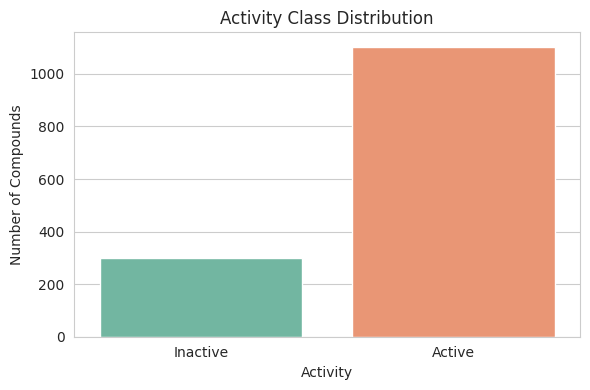

In [31]:
# 5. Statistical plots
# ---------------------------------------------------
sns.set_style("whitegrid")

# Active/inactive compound count
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="activity", palette="Set2")
plt.xticks([0, 1], ["Inactive", "Active"])
plt.title("Activity Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Compounds")
plt.tight_layout()
plt.savefig("activity_distribution.png", dpi=300)
plt.show()

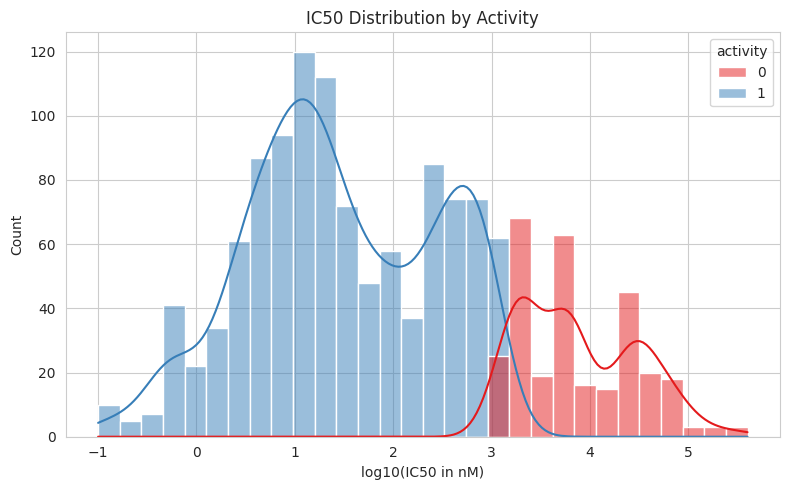

In [32]:
# IC50 distribution
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="log10_IC50_nM",
    hue="activity",
    bins=30,
    kde=True,
    palette="Set1"
)
plt.title("IC50 Distribution by Activity")
plt.xlabel("log10(IC50 in nM)")
plt.tight_layout()
plt.savefig("ic50_distribution.png", dpi=300)
plt.show()


/tmp/ipykernel_9057/2359846162.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="activity", y=column, ax=ax, palette="Set2")
/tmp/ipykernel_9057/2359846162.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Inactive", "Active"])
/tmp/ipykernel_9057/2359846162.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="activity", y=column, ax=ax, palette="Set2")
/tmp/ipykernel_9057/2359846162.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Inactive", "Active"])


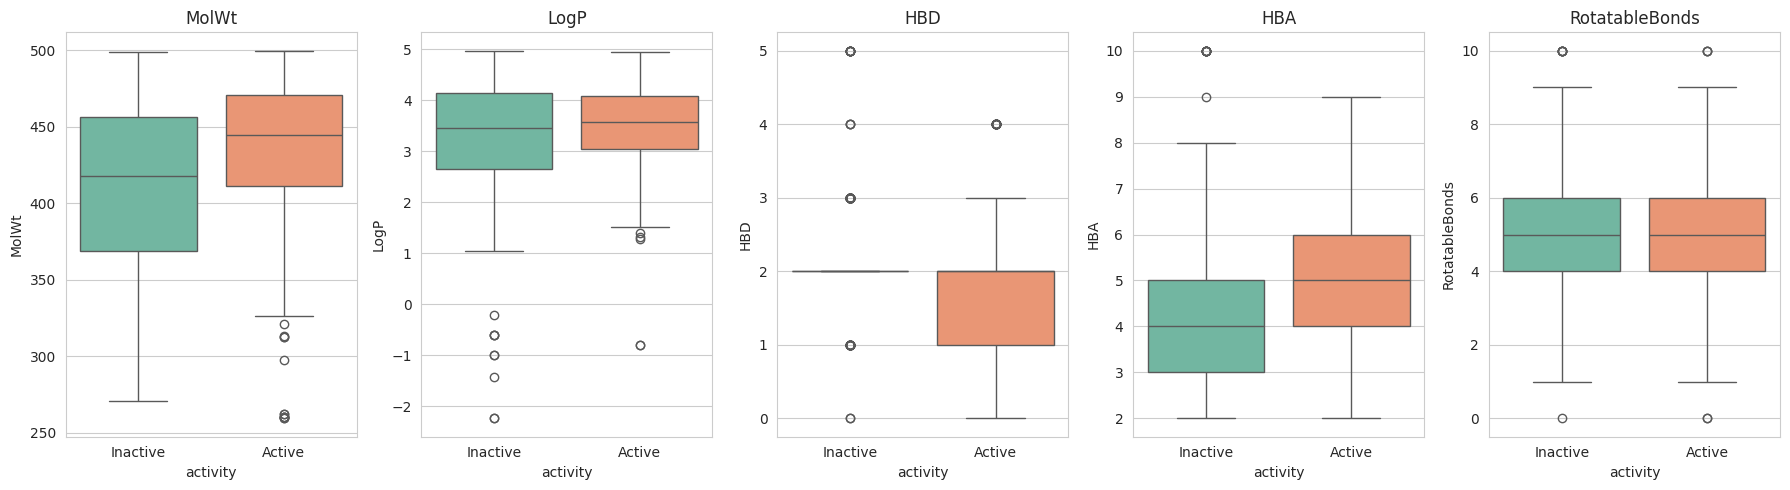

In [33]:
# Drug descriptor boxplots
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, column in zip(axes, drug_descriptor_columns):
    sns.boxplot(data=df, x="activity", y=column, ax=ax, palette="Set2")
    ax.set_xticklabels(["Inactive", "Active"])
    ax.set_title(column)

plt.tight_layout()
plt.savefig("drug_descriptor_boxplots.png", dpi=300)
plt.show()

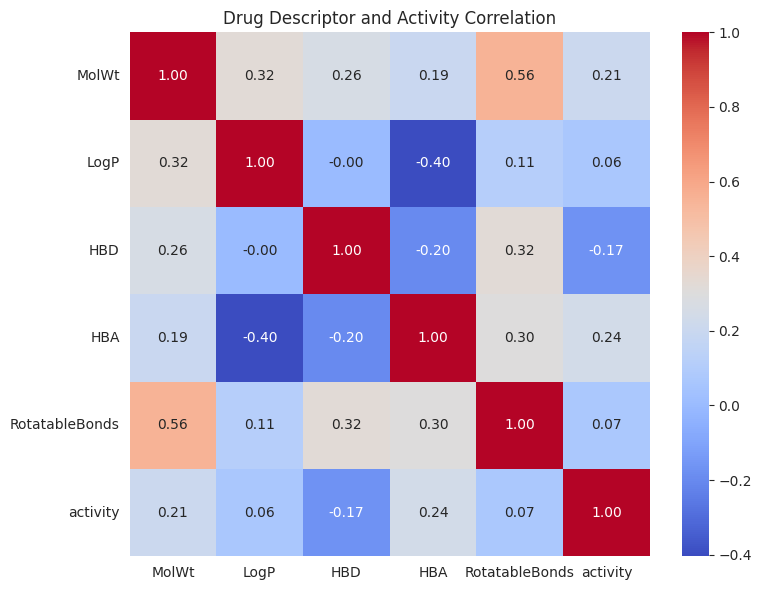

In [34]:
# Correlation between drug descriptors and activity
plt.figure(figsize=(8, 6))

correlation_data = df[drug_descriptor_columns + ["activity"]].corr(
    method="spearman"
)

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Drug Descriptor and Activity Correlation")
plt.tight_layout()
plt.savefig("descriptor_activity_correlation.png", dpi=300)
plt.show()

In [35]:
# 6. Prepare data for machine learning
# ---------------------------------------------------
# Remove IC50_nM and pIC50_normalized from features.
# They would cause data leakage because activity comes from IC50_nM.
df = df.dropna(subset=feature_columns + ["activity"])

X = df[feature_columns].apply(pd.to_numeric, errors="coerce")
y = df["activity"]

# 80% training data, 20% test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


### Splitting Only Active Compounds
Below, we filter our dataset to keep only the active compounds (`activity == 1`) and then split this subset into training and testing sets.

In [36]:
# Filter dataset for active compounds only
df_active = df[df["activity"] == 1].dropna(subset=feature_columns)

X_active = df_active[feature_columns].apply(pd.to_numeric, errors="coerce")
y_active = df_active["activity"]

# Split only the active compounds (80% train, 20% test)
X_train_active, X_test_active, y_train_active, y_test_active = train_test_split(
    X_active,
    y_active,
    test_size=0.20,
    random_state=42
)

print("Active dataset shape:", df_active.shape)
print("Active training samples:", X_train_active.shape[0])
print("Active test samples:", X_test_active.shape[0])

Active dataset shape: (1103, 2089)
Active training samples: 882
Active test samples: 221


In [37]:
from sklearn.feature_selection import VarianceThreshold

# 7. Logistic Regression baseline model
# VarianceThreshold removes all constant protein features.
# ---------------------------------------------------
logistic_model = Pipeline([
      ("imputer", SimpleImputer(strategy="median")),
      ("remove_constant_features", VarianceThreshold(threshold=0)),
      ("scaler", StandardScaler()),
      ("model", LogisticRegression(
          max_iter=5000,
          class_weight="balanced",
          random_state=42
      ))
])

logistic_model.fit(X_train, y_train)

logistic_prediction = logistic_model.predict(X_test)
logistic_probability = logistic_model.predict_proba(X_test)[:, 1]

print("\n---------- Logistic Regression ----------")
print(classification_report(y_test, logistic_prediction))


---------- Logistic Regression ----------
              precision    recall  f1-score   support

           0       0.84      0.77      0.80        60
           1       0.94      0.96      0.95       221

    accuracy                           0.92       281
   macro avg       0.89      0.86      0.87       281
weighted avg       0.92      0.92      0.92       281



In [38]:
# 8. Random Forest model
# ---------------------------------------------------
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("remove_constant_features", VarianceThreshold(threshold=0)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_prediction = random_forest_model.predict(X_test)
rf_probability = random_forest_model.predict_proba(X_test)[:, 1]

print("\n---------- Random Forest ----------")
print(classification_report(y_test, rf_prediction))


---------- Random Forest ----------
              precision    recall  f1-score   support

           0       0.80      0.88      0.84        60
           1       0.97      0.94      0.95       221

    accuracy                           0.93       281
   macro avg       0.89      0.91      0.90       281
weighted avg       0.93      0.93      0.93       281



### Confusion Matrix Comparison
We will now generate and visualize the confusion matrices for both models to inspect their performance on each class.

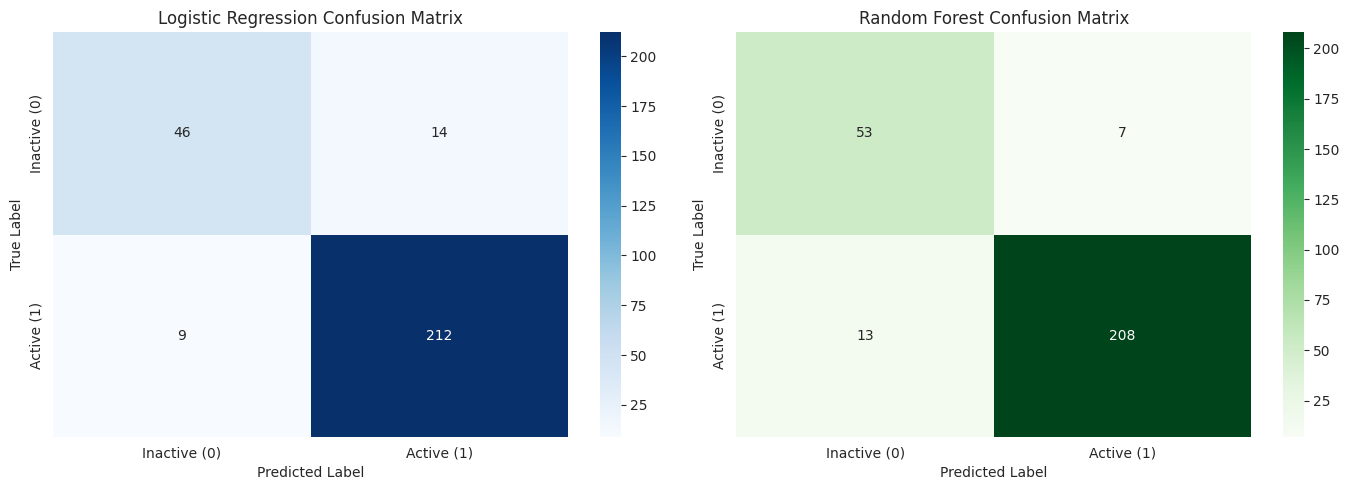

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute confusion matrices
cm_logistic = confusion_matrix(y_test, logistic_prediction)
cm_rf = confusion_matrix(y_test, rf_prediction)

# Plot both confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
sns.heatmap(cm_logistic, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Inactive (0)", "Active (1)"],
            yticklabels=["Inactive (0)", "Active (1)"])
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Random Forest Confusion Matrix
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Inactive (0)", "Active (1)"],
            yticklabels=["Inactive (0)", "Active (1)"])
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("model_confusion_matrices.png", dpi=300)
plt.show()